In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


Set project paths

In [7]:
# Detect the project root whether the notebook kernel starts in the project folder or src/
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "database").exists():
    PROJECT_DIR = PROJECT_DIR.parent

DATABASE_FILE = PROJECT_DIR / "database" / "chicago_crime.db"
REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Define the chart output folder BEFORE any chart is created or saved.
CHARTS_DIR = REPORTS_DIR / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Database exists:", DATABASE_FILE.exists())
print("Reports directory:", REPORTS_DIR)
print("Charts directory:", CHARTS_DIR)


Project folder: c:\Users\sapni\OneDrive\Desktop\Chicago_Crime_Capstone
Database exists: True
Reports directory: c:\Users\sapni\OneDrive\Desktop\Chicago_Crime_Capstone\reports
Charts directory: c:\Users\sapni\OneDrive\Desktop\Chicago_Crime_Capstone\reports\charts


Load the saved analysis results
We will reuse the CSV files created in our earlier notebooks rather than repeat the analysis.

In [8]:
yearly_crimes = pd.read_csv(
    REPORTS_DIR / "yearly_crime_counts.csv"
)

top_10_crimes = pd.read_csv(
    REPORTS_DIR / "top_10_crime_categories.csv"
)

yearly_arrests = pd.read_csv(
    REPORTS_DIR / "yearly_arrest_rates.csv"
)

monthly_crimes = pd.read_csv(
    REPORTS_DIR / "monthly_crime_counts.csv"
)

top_10_communities = pd.read_csv(
    REPORTS_DIR / "top_10_community_areas.csv"
)

sql_yearly = pd.read_csv(
    REPORTS_DIR / "sql_yearly_crime_summary.csv"
)

sql_categories = pd.read_csv(
    REPORTS_DIR / "sql_crime_category_summary.csv"
)

print("All saved analysis results loaded successfully!")

All saved analysis results loaded successfully!


In [9]:
print("Annual crime summary:")
display(yearly_crimes)

print("Top crime categories:")
display(top_10_crimes)

print("Yearly arrest rates:")
display(yearly_arrests)

print("Monthly crime counts:")
display(monthly_crimes)

print("Top community areas:")
display(top_10_communities)

Annual crime summary:


,Year,Total_Crimes
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,490


Top crime categories:


,Primary_Type,Crime_Count,Percentage
0,THEFT,105,21.084337
1,BATTERY,85,17.068273
2,CRIMINAL DAMAGE,49,9.839357
3,OTHER OFFENSE,39,7.831325
4,DECEPTIVE PRACTICE,38,7.630522
5,ASSAULT,35,7.028112
6,NARCOTICS,32,6.425703
7,ROBBERY,30,6.024096
8,CRIMINAL TRESPASS,17,3.413655
9,MOTOR VEHICLE THEFT,16,3.212851


Yearly arrest rates:


,Year,Total_Crimes,Total_Arrests,Arrest_Rate
0,2012,2,2,100.000000
1,2013,1,1,100.000000
2,2014,1,0,0.000000
3,2015,4,2,50.000000
4,2016,490,119,24.285714


Monthly crime counts:


,Month,Total_Crimes
0,1,10
1,2,5
2,3,12
3,4,22
4,5,447
5,11,2


Top community areas:


,community_name,community_code,Crime_Count,Percentage
0,Austin,25,34,6.827309
1,Humboldt Park,23,20,4.016064
2,Near North Side,8,20,4.016064
3,South Lawndale,30,16,3.212851
4,South Shore,43,16,3.212851
5,Englewood,68,16,3.212851
6,Loop,32,15,3.012048
7,Auburn Gresham,71,14,2.811245
8,Lake View,6,14,2.811245
9,Roseland,49,14,2.811245


Build the consolidated visualizations

Annual crime trends

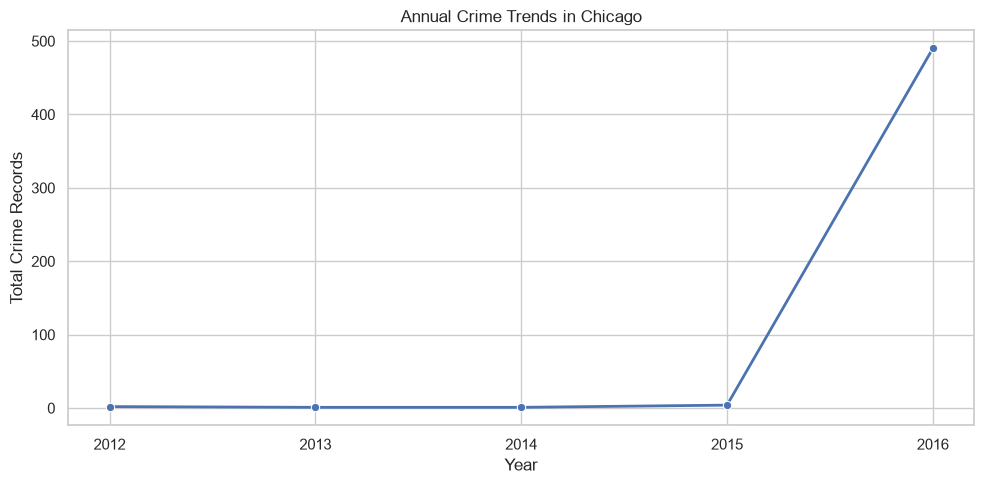

In [10]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_crimes,
    x="Year",
    y="Total_Crimes",
    marker="o",
    linewidth=2
)

plt.title("Annual Crime Trends in Chicago")
plt.xlabel("Year")
plt.ylabel("Total Crime Records")
plt.xticks(yearly_crimes["Year"])
plt.tight_layout()
plt.savefig(CHARTS_DIR / "annual_crime_trends.png", dpi=300, bbox_inches="tight")
plt.show()

Annual Crime Trends

This visualization shows the number of recorded crime incidents for each year in the dataset.

In [11]:
print(yearly_crimes.columns.tolist())
print(yearly_crimes.head())

['Year', 'Total_Crimes']
   Year  Total_Crimes
0  2012             2
1  2013             1
2  2014             1
3  2015             4
4  2016           490


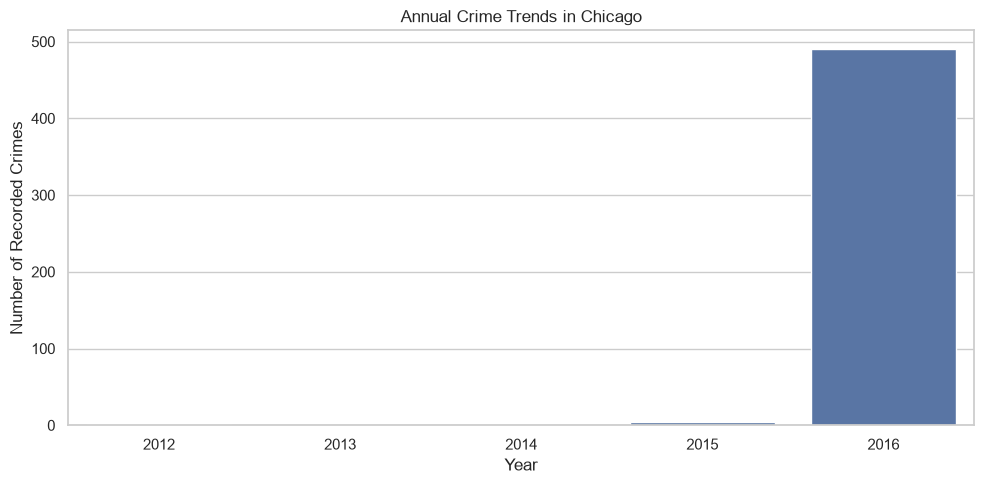

In [12]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_crimes,
    x="Year",
    y="Total_Crimes"
)

plt.title("Annual Crime Trends in Chicago")
plt.xlabel("Year")
plt.ylabel("Number of Recorded Crimes")
plt.tight_layout()

plt.show()

Top 10 crime categories

In [13]:
print(top_10_crimes.columns.tolist())
display(top_10_crimes.head())

['Primary_Type', 'Crime_Count', 'Percentage']


,Primary_Type,Crime_Count,Percentage
0,THEFT,105,21.084337
1,BATTERY,85,17.068273
2,CRIMINAL DAMAGE,49,9.839357
3,OTHER OFFENSE,39,7.831325
4,DECEPTIVE PRACTICE,38,7.630522


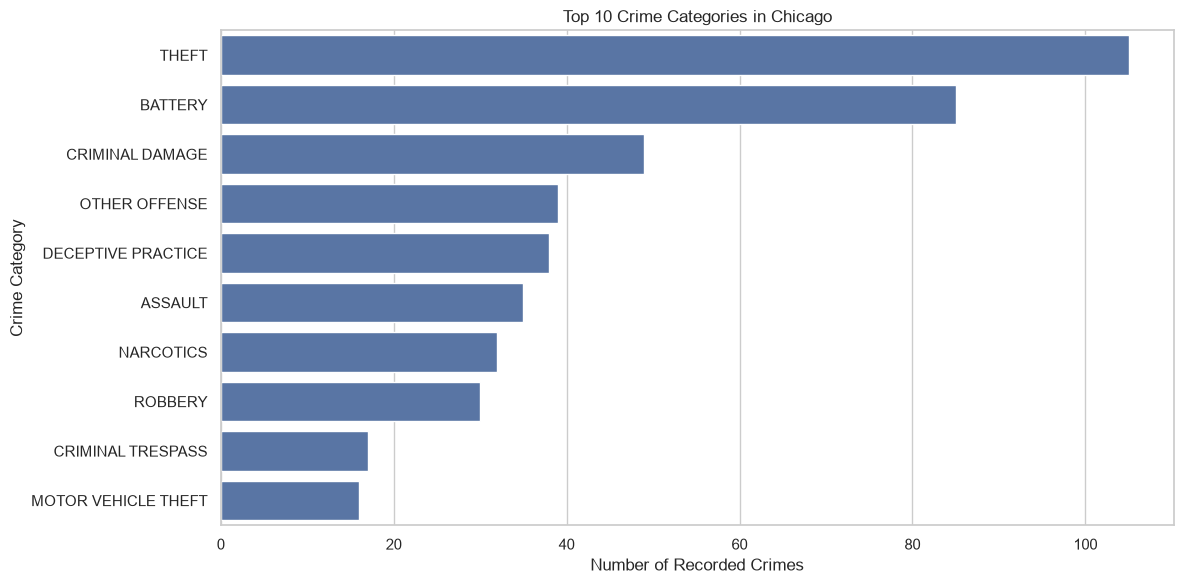

In [15]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_crimes,
    x="Crime_Count",
    y="Primary_Type"
)

plt.title("Top 10 Crime Categories in Chicago")
plt.xlabel("Number of Recorded Crimes")
plt.ylabel("Crime Category")
plt.tight_layout()

plt.savefig(CHARTS_DIR / "top_10_crime_categories.png", dpi=300, bbox_inches="tight")
plt.show()

Yearly arrest rates

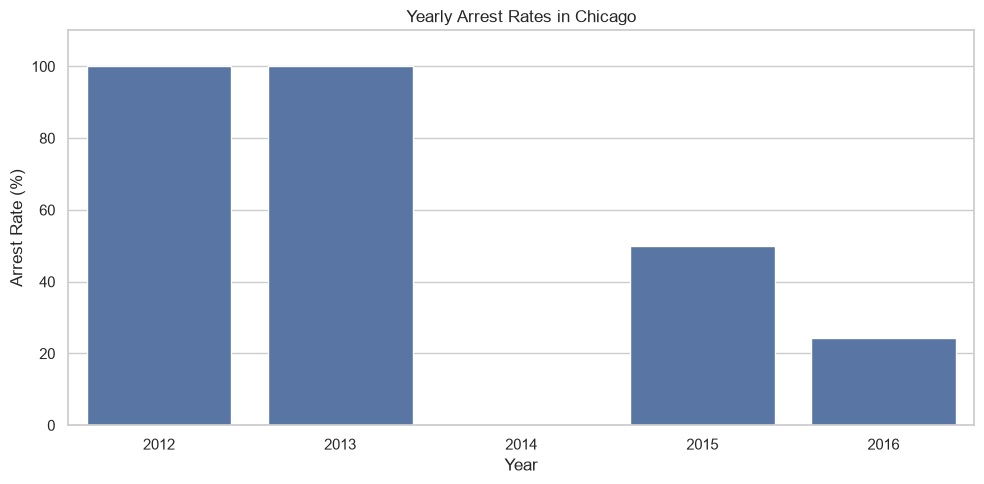

In [16]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_arrests,
    x="Year",
    y="Arrest_Rate"
)

plt.title("Yearly Arrest Rates in Chicago")
plt.xlabel("Year")
plt.ylabel("Arrest Rate (%)")
plt.ylim(0, 110)

plt.tight_layout()
plt.savefig(CHARTS_DIR / "yearly_arrest_rates.png", dpi=300, bbox_inches="tight")
plt.show()

Monthly crime distribution

['Month', 'Total_Crimes']


,Month,Total_Crimes
0,1,10
1,2,5
2,3,12
3,4,22
4,5,447
5,11,2


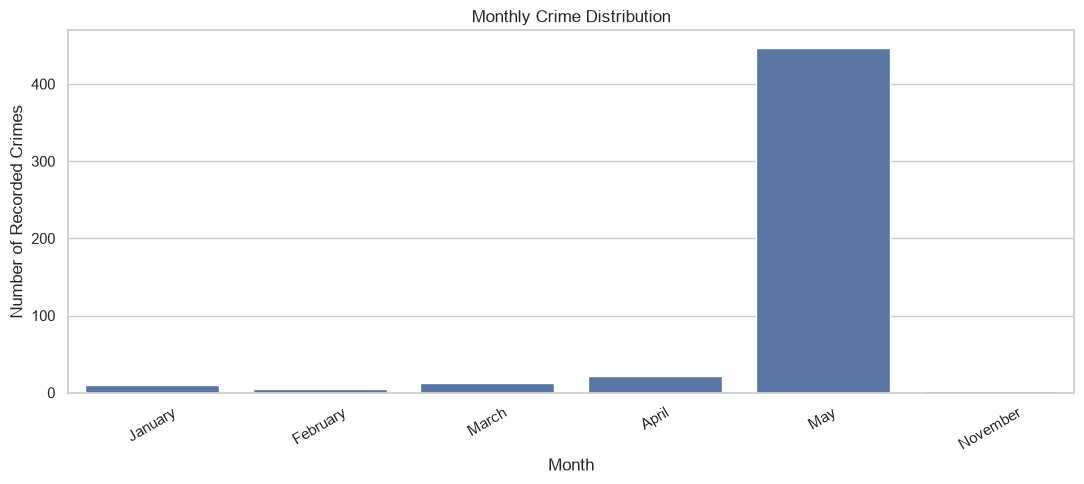

In [17]:
print(monthly_crimes.columns.tolist())
display(monthly_crimes)

month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    11: "November"
}

monthly_crimes["Month_Name"] = monthly_crimes["Month"].map(month_names)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=monthly_crimes,
    x="Month_Name",
    y="Total_Crimes",
    order=["January", "February", "March", "April", "May", "November"]
)

plt.title("Monthly Crime Distribution")
plt.xlabel("Month")
plt.ylabel("Number of Recorded Crimes")
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig(CHARTS_DIR / "monthly_crime_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

Top 10 community areas

['community_name', 'community_code', 'Crime_Count', 'Percentage']


,community_name,community_code,Crime_Count,Percentage
0,Austin,25,34,6.827309
1,Humboldt Park,23,20,4.016064
2,Near North Side,8,20,4.016064
3,South Lawndale,30,16,3.212851
4,South Shore,43,16,3.212851
5,Englewood,68,16,3.212851
6,Loop,32,15,3.012048
7,Auburn Gresham,71,14,2.811245
8,Lake View,6,14,2.811245
9,Roseland,49,14,2.811245


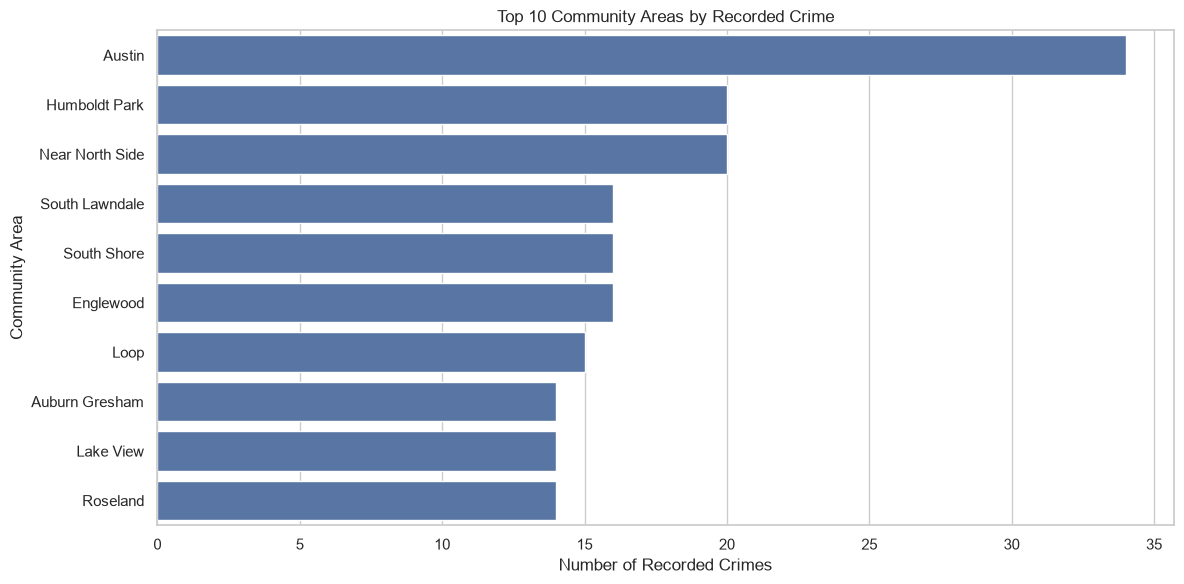

In [18]:
print(top_10_communities.columns.tolist())
display(top_10_communities)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_communities,
    x="Crime_Count",
    y="community_name"
)

plt.title("Top 10 Community Areas by Recorded Crime")
plt.xlabel("Number of Recorded Crimes")
plt.ylabel("Community Area")

plt.tight_layout()
plt.savefig(CHARTS_DIR / "top_10_community_areas.png", dpi=300, bbox_inches="tight")
plt.show()

Crime Distribution by Month and Day of Week

This heatmap shows how recorded incidents are distributed across months and weekdays.

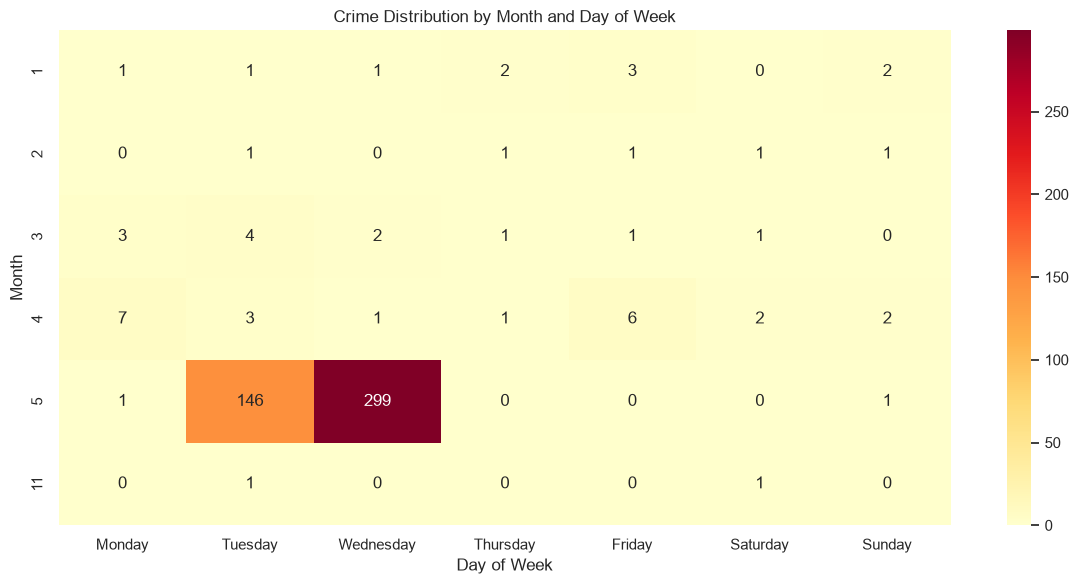

In [19]:
import sqlite3

DB_PATH = PROJECT_DIR / "database" / "chicago_crime.db"

conn = sqlite3.connect(DB_PATH)

crime_dates = pd.read_sql_query(
    """
    SELECT date
    FROM chicago_crime
    """,
    conn
)

conn.close()

crime_dates["date"] = pd.to_datetime(crime_dates["date"], errors="coerce")

crime_dates["Month"] = crime_dates["date"].dt.month
crime_dates["DayOfWeek"] = crime_dates["date"].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

heatmap_data = pd.crosstab(
    crime_dates["Month"],
    crime_dates["DayOfWeek"]
).reindex(columns=weekday_order, fill_value=0)

plt.figure(figsize=(12, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="YlOrRd"
)

plt.title("Crime Distribution by Month and Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Month")

plt.tight_layout()
plt.savefig(CHARTS_DIR / "monthly_weekday_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

Community Area Crime Distribution – Boxplot

This boxplot displays the distribution of recorded crime counts across community areas and helps identify statistical outliers using the IQR method.

Q1: 3.0
Q3: 9.0
IQR: 6.0
Lower Bound: -6.0
Upper Bound: 18.0

Outlier community areas:


,community_code,Crime_Count
13,23,20
15,25,34
68,8,20


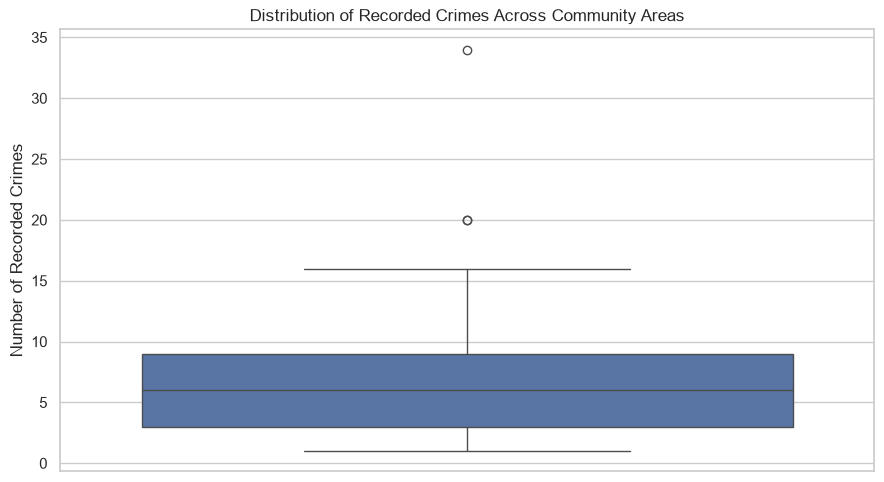

In [20]:
# Count recorded crimes in each community area
community_counts = pd.read_sql_query(
    """
    SELECT
        community_code,
        COUNT(*) AS Crime_Count
    FROM chicago_crime
    WHERE community_code IS NOT NULL
    GROUP BY community_code
    """,
    sqlite3.connect(DB_PATH)
)

# Calculate quartiles and IQR
Q1 = community_counts["Crime_Count"].quantile(0.25)
Q3 = community_counts["Crime_Count"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Identify outliers
outliers = community_counts[
    (community_counts["Crime_Count"] < lower_bound) |
    (community_counts["Crime_Count"] > upper_bound)
]

print("\nOutlier community areas:")
display(outliers)

# Create boxplot
plt.figure(figsize=(9, 5))

sns.boxplot(
    y=community_counts["Crime_Count"]
)

plt.title("Distribution of Recorded Crimes Across Community Areas")
plt.ylabel("Number of Recorded Crimes")

plt.tight_layout()
plt.savefig(CHARTS_DIR / "community_area_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

Correlation Analysis

This heatmap examines correlations between selected numeric variables, including geographic coordinates, year, month, arrest status, and domestic incident status.

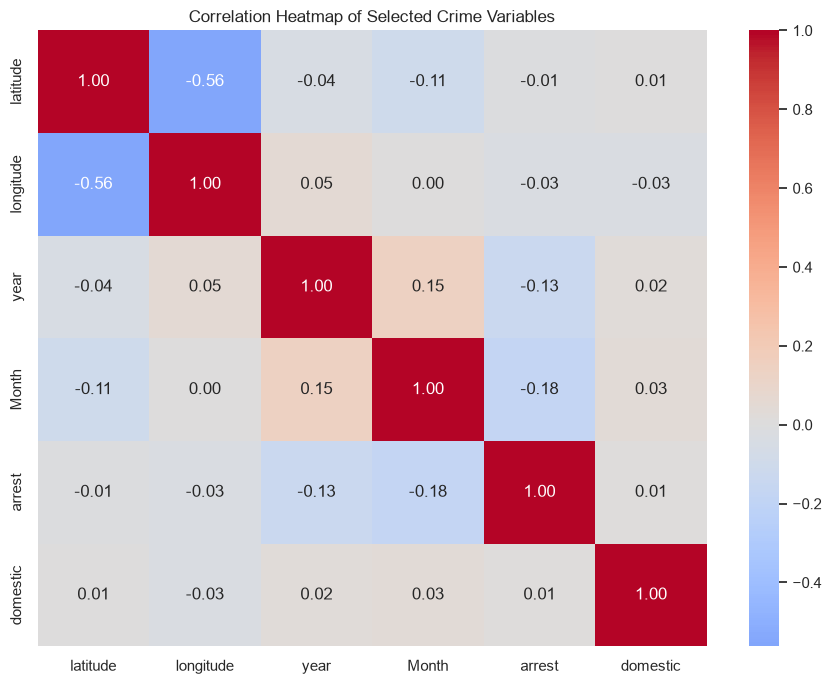

In [21]:
conn = sqlite3.connect(DB_PATH)

correlation_data = pd.read_sql_query(
    """
    SELECT
        latitude,
        longitude,
        year,
        Month,
        arrest,
        domestic
    FROM chicago_crime
    """,
    conn
)

conn.close()

# Convert Boolean fields to numeric values
correlation_data["arrest"] = correlation_data["arrest"].astype(float)
correlation_data["domestic"] = correlation_data["domestic"].astype(float)

# Calculate correlation matrix
correlation_matrix = correlation_data.corr(numeric_only=True)

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Selected Crime Variables")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

Save All Visualizations

Save the charts generated for Use Cases 2 and 3 for reuse in the Streamlit dashboard.

In [22]:
CHARTS_DIR = REPORTS_DIR / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

print("Charts folder:", CHARTS_DIR)

Charts folder: c:\Users\sapni\OneDrive\Desktop\Chicago_Crime_Capstone\reports\charts


In [23]:
saved_charts = list(CHARTS_DIR.glob("*.png"))

print("Number of saved charts:", len(saved_charts))

for chart in sorted(saved_charts):
    print(chart.name)

Number of saved charts: 8
annual_crime_trends.png
community_area_boxplot.png
correlation_heatmap.png
monthly_crime_distribution.png
monthly_weekday_heatmap.png
top_10_community_areas.png
top_10_crime_categories.png
yearly_arrest_rates.png
